# 03 – Kernel PCA with four kernel families

**Aim.** Compute kPCA with a linear, polynomial (degree 2 and 3), Gaussian (RBF) and Cauchy kernel, check
that the computation is right, and see how each kernel reshapes the data compared with linear PCA
(notebook 02). Every kernel uses a standard default setting here; the settings are tuned in notebook 04.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.decomposition import KernelPCA
from sklearn.preprocessing import KernelCenterer

import kpca_tools as kt

FIG_DIR = "figures"
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 200, "font.size": 9,
                     "axes.spines.top": False, "axes.spines.right": False})

X_raw, y = kt.load_meter_b()
X = X_raw[:, np.setdiff1d(np.arange(X_raw.shape[1]), kt.constant_columns(X_raw))]   # same as notebook 01
Z, mu, sigma = kt.zscore(X)
n, p = Z.shape
print("Z:", Z.shape)

Z: (92, 51)


## 2. Kernel settings


In [2]:
sig = kt.median_distance(Z)
print(f"Median distance between samples: sigma = {sig:.3f}")
print(f"RBF gamma = 1/(2 sigma^2) = {1 / (2 * sig ** 2):.5f};  polynomial gamma = 1/p = {1 / p:.4f}")

KERNELS = {                        # name: arguments for kt.kernel_matrix
    "Linear":     dict(kind="linear"),
    "Poly d=2":   dict(kind="poly", degree=2),
    "Poly d=3":   dict(kind="poly", degree=3),
    "Gaussian":   dict(kind="rbf", sigma=sig),
    "Cauchy":     dict(kind="cauchy", sigma=sig),
}

res = {}
for name, args in KERNELS.items():
    K = kt.kernel_matrix(Z, **args)
    scores, lam, evr, model = kt.kpca(K)
    res[name] = dict(K=K, T=scores, lam=lam, evr=evr)
    print(f"{name:<9} kept components: {scores.shape[1]}")

Median distance between samples: sigma = 7.747
RBF gamma = 1/(2 sigma^2) = 0.00833;  polynomial gamma = 1/p = 0.0196
Linear    kept components: 47
Poly d=2  kept components: 91
Poly d=3  kept components: 91
Gaussian  kept components: 91
Cauchy    kept components: 91


## 3. Checks

In [3]:
T_pca, P_pca, lam_pca, evr_pca = kt.pca(Z)
r = 47                                            # number of non-zero eigenvalues of linear PCA

# (a) linear-kernel kPCA reproduces linear PCA (scores up to sign; eigenvalues differ by the factor n-1)
lin = res["Linear"]
assert np.allclose(np.abs(lin["T"][:, :r]), np.abs(T_pca[:, :r]))
assert np.allclose(lin["lam"][:r] / (n - 1), lam_pca[:r])
assert np.allclose(lin["evr"][:r], evr_pca[:r])

# (b) centring: KernelCenterer equals the formula, and every row of Kc sums to 0
K = res["Gaussian"]["K"]
H = np.eye(n) - np.ones((n, n)) / n
Kc = KernelCenterer().fit_transform(K)
assert np.allclose(Kc, H @ K @ H)
assert np.allclose(Kc.sum(axis=1), 0)

# (c) scikit-learn's eigenvalues and scores equal a direct eigendecomposition of Kc
w, U = np.linalg.eigh(Kc)
w, U = w[::-1], U[:, ::-1]                        # largest first
assert np.allclose(res["Gaussian"]["lam"][:10], w[:10])
assert np.allclose(np.abs(res["Gaussian"]["T"][:, :10]), np.abs(U[:, :10] * np.sqrt(w[:10])))

# (d) the Cauchy kernel matrix equals its formula
D2 = ((Z[:, None, :] - Z[None, :, :]) ** 2).sum(axis=2)
assert np.allclose(res["Cauchy"]["K"], 1 / (1 + D2 / sig ** 2))

# (e) the precomputed Gaussian kernel gives the same kPCA as scikit-learn's built-in "rbf"
T_builtin = KernelPCA(kernel="rbf", gamma=1 / (2 * sig ** 2)).fit_transform(Z)
assert np.allclose(np.abs(T_builtin[:, :10]), np.abs(res["Gaussian"]["T"][:, :10]))

print("All kPCA checks passed.")

All kPCA checks passed.


## 4. Kernel matrices

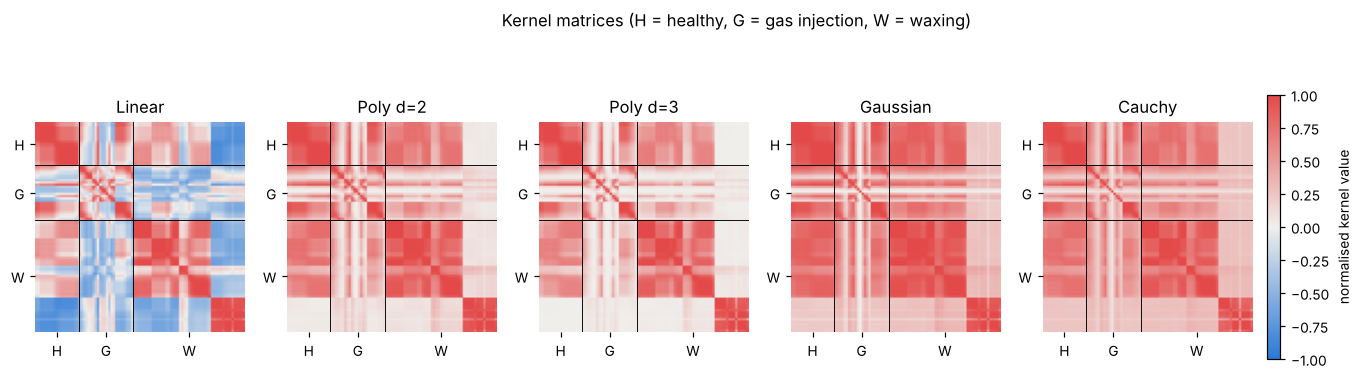

In [4]:
bounds = np.cumsum([np.sum(y == c) for c in kt.CLASS_NAMES])[:-1] - 0.5
mids = [np.mean(np.where(y == c)[0]) for c in kt.CLASS_NAMES]

fig, axes = plt.subplots(1, 5, figsize=(17, 3.9))
for ax, (name, r_) in zip(axes, res.items()):
    K = r_["K"]
    d = np.sqrt(np.diag(K))
    im = ax.imshow(K / np.outer(d, d), cmap=kt.DIVERGING_CMAP, vmin=-1, vmax=1)
    for b in bounds:
        ax.axhline(b, color="k", lw=0.6)
        ax.axvline(b, color="k", lw=0.6)
    ax.set_xticks(mids, ["H", "G", "W"])
    ax.set_yticks(mids, ["H", "G", "W"])
    ax.set_title(name)
    ax.spines[:].set_visible(False)
fig.colorbar(im, ax=axes, shrink=0.8, pad=0.01, label="normalised kernel value")
fig.suptitle("Kernel matrices (H = healthy, G = gas injection, W = waxing)", y=1.0)
fig.savefig(f"{FIG_DIR}/m3_kernel_matrices.png", bbox_inches="tight")
plt.show()

## 5. Explained variance per kernel
Share of the feature-space variance captured by each kPC. Note that for the non-linear kernels this is
variance in a *different space* for each kernel, so the numbers describe how concentrated each kernel's
own structure is, not which kernel is better.

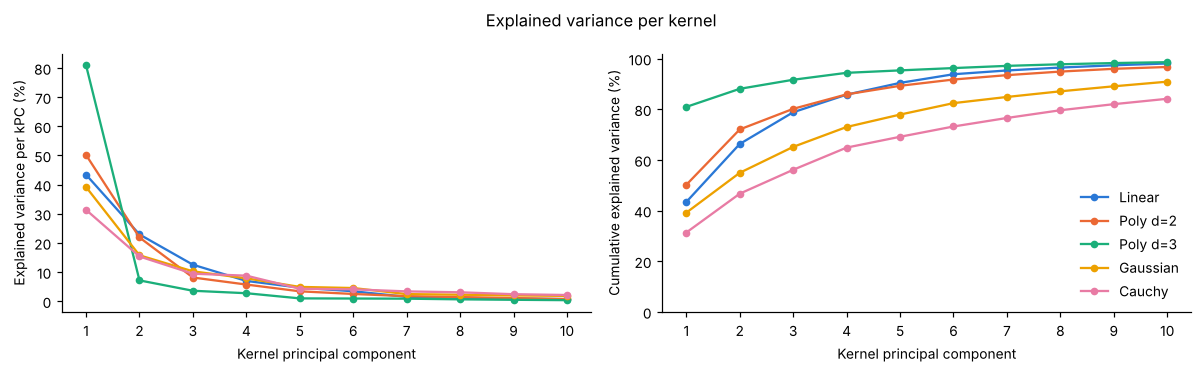

kernel       kPC1   kPC2   kPC3  kPC1-3  kPC1-7
Linear       43.4   22.9   12.5    78.8    95.3
Poly d=2     50.2   21.9    8.1    80.2    93.5
Poly d=3     80.9    7.1    3.6    91.6    97.1
Gaussian     39.2   15.7   10.2    65.2    84.9
Cauchy       31.3   15.3    9.4    56.1    76.6


In [5]:
KERNEL_COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"]   # fixed order, one per kernel
n_show = 10

fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
for (name, r_), col in zip(res.items(), KERNEL_COLORS):
    evr = r_["evr"]
    axes[0].plot(range(1, n_show + 1), 100 * evr[:n_show], marker="o", ms=4, lw=1.5, color=col, label=name)
    axes[1].plot(range(1, n_show + 1), 100 * np.cumsum(evr)[:n_show], marker="o", ms=4, lw=1.5, color=col, label=name)
axes[0].set_ylabel("Explained variance per kPC (%)")
axes[1].set_ylabel("Cumulative explained variance (%)")
axes[1].set_ylim(0, 102)
for ax in axes:
    ax.set_xlabel("Kernel principal component")
    ax.set_xticks(range(1, n_show + 1))
axes[1].legend(frameon=False, loc="lower right")
fig.suptitle("Explained variance per kernel")
fig.tight_layout()
fig.savefig(f"{FIG_DIR}/m3_scree.png")
plt.show()

print(f"{'kernel':<10}{'kPC1':>7}{'kPC2':>7}{'kPC3':>7}{'kPC1-3':>8}{'kPC1-7':>8}")
for name, r_ in res.items():
    e = 100 * r_["evr"]
    print(f"{name:<10}{e[0]:7.1f}{e[1]:7.1f}{e[2]:7.1f}{e[:3].sum():8.1f}{e[:7].sum():8.1f}")

## 6. Score plots
Scores on kPC1–kPC2, kPC1–kPC3 and kPC2–kPC3 for every kernel. The linear row is identical to notebook 02
(possibly with flipped signs, which carry no meaning).

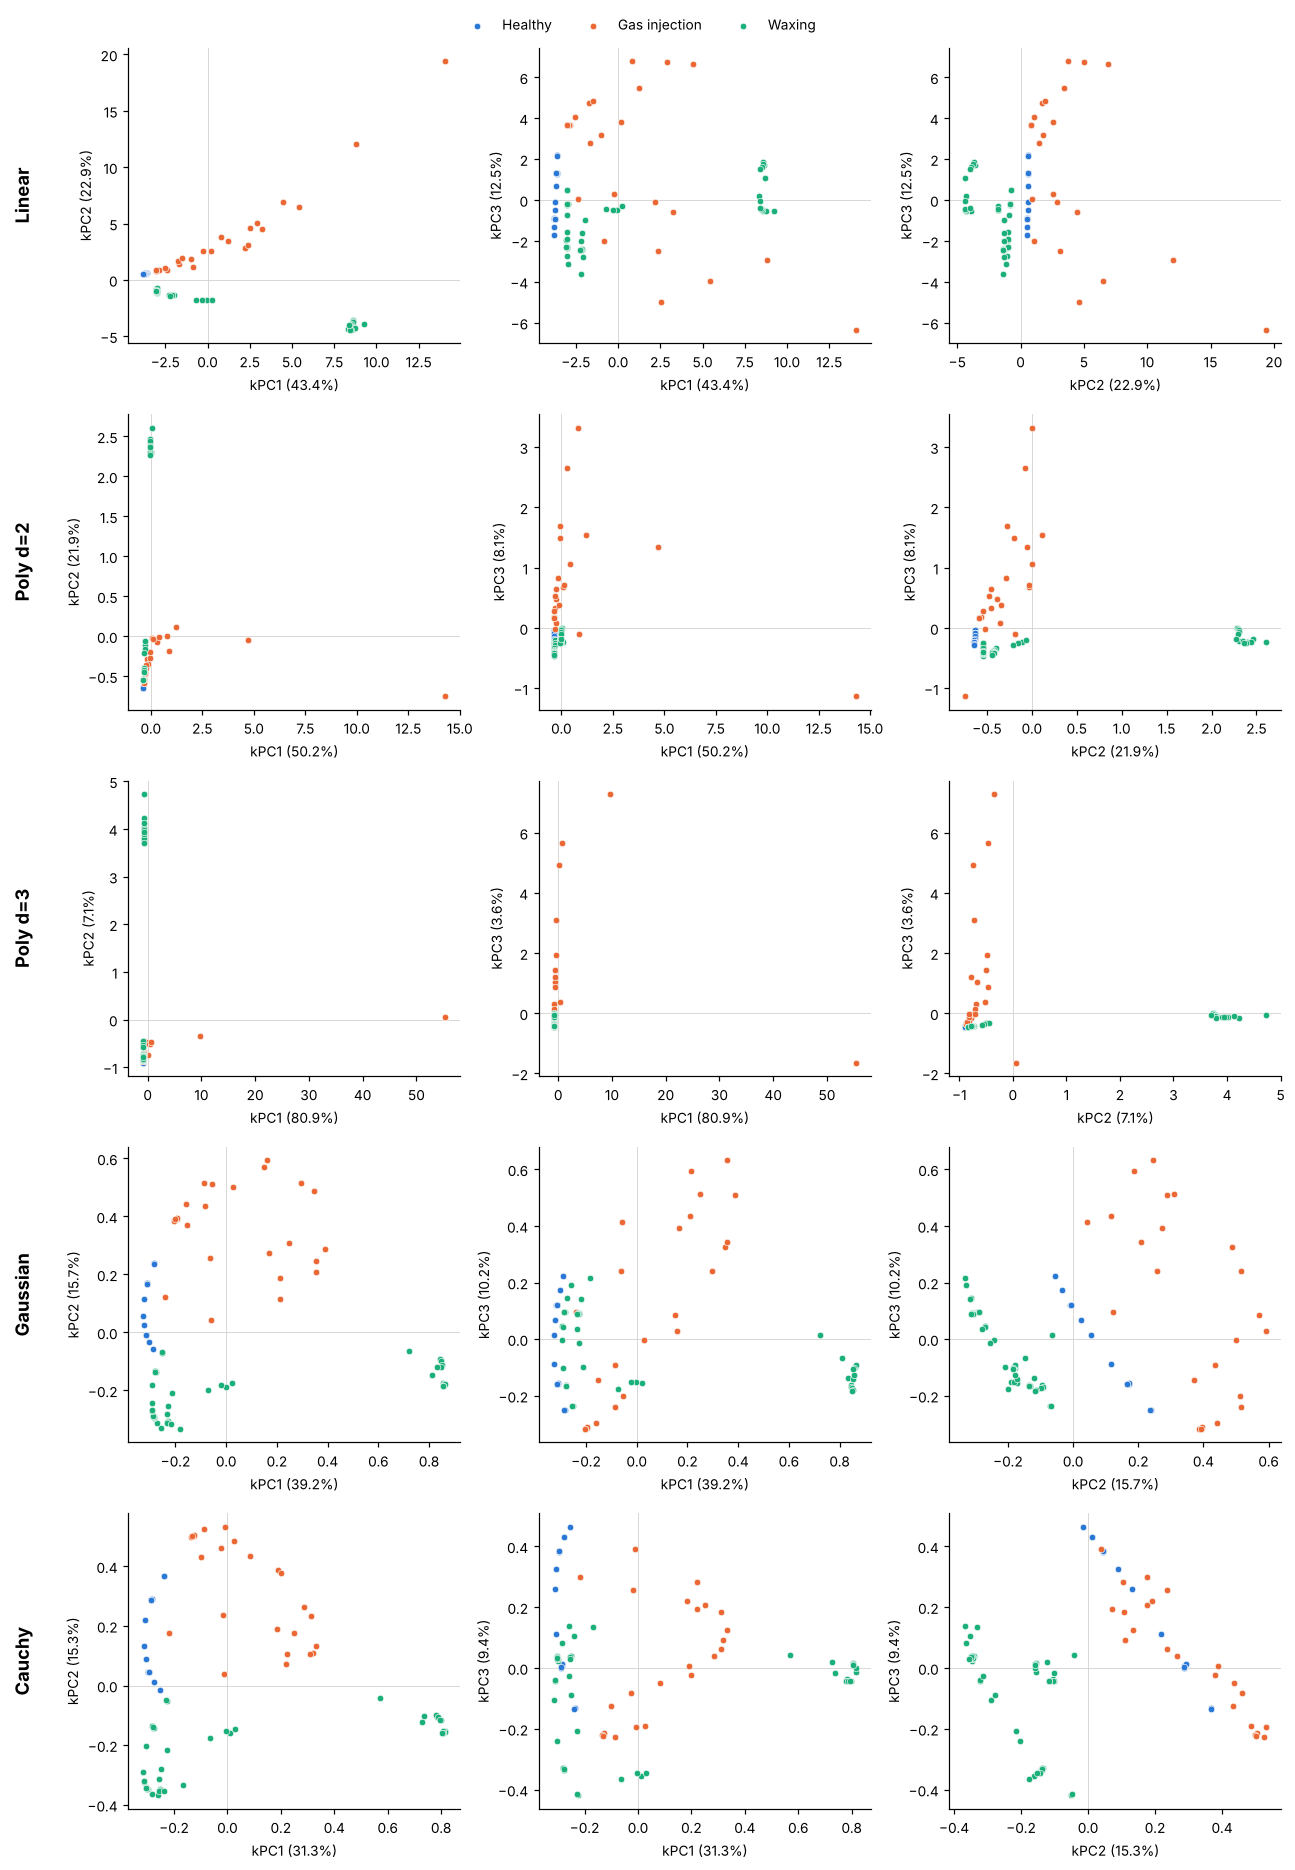

In [6]:
planes = [(0, 1), (0, 2), (1, 2)]
fig, axes = plt.subplots(len(res), 3, figsize=(12, 3.4 * len(res)))
for row, (name, r_) in zip(axes, res.items()):
    T, evr = r_["T"], r_["evr"]
    for ax, (i, j) in zip(row, planes):
        for c in kt.CLASS_NAMES:
            m = y == c
            ax.scatter(T[m, i], T[m, j], s=18, color=kt.CLASS_COLORS[c], edgecolor=kt.SURFACE,
                       linewidth=0.4, label=kt.CLASS_NAMES[c])
        ax.axhline(0, color="#d6d5d0", lw=0.6, zorder=0)
        ax.axvline(0, color="#d6d5d0", lw=0.6, zorder=0)
        ax.set_xlabel(f"kPC{i + 1} ({evr[i]:.1%})")
        ax.set_ylabel(f"kPC{j + 1} ({evr[j]:.1%})")
    row[0].annotate(name, xy=(-0.32, 0.5), xycoords="axes fraction", rotation=90,
                    ha="center", va="center", fontsize=12, fontweight="bold")
handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper center", ncol=3, frameon=False, bbox_to_anchor=(0.5, 1.0))
fig.tight_layout(rect=(0.02, 0, 1, 0.985))
fig.savefig(f"{FIG_DIR}/m3_scores.png")
plt.show()